<a href="https://colab.research.google.com/github/sergioqfun/code-novatadas/blob/main/Graficos_farmaco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CONECTAR A TU DRIVE**

*   Ejecutarlo en un entorno de python

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**1_RMSD**

In [ ]:
#INSTALACION DE PAQUETES
options(repos = c(CRAN = "https://cloud.r-project.org")) # es la opción que le dice a R de qué repositorios descargar paquetes.
install.packages(c("ggExtra","dplyr","car","latex2exp","gridExtra","lattice","ggplot2","MASS","viridisLite"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘xts’, ‘TTR’, ‘quadprog’, ‘quantmod’, ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘tseries’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘microbenchmark’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘Rdpack’, ‘RcppEigen’, ‘colourpicker’, ‘shinyjs’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’




In [ ]:
# library
library(ggplot2)
library(latex2exp)
library(ggExtra)

library(gridExtra)
library(grid)
library(lattice)


########################################
############  RMSD
########################################

data <- read.table(file = "/home/rmsd_backbone.xvg", header = TRUE)
data["time_ns"] <- data$time*20

plot <- ggplot(data,aes(time_ns,rmsd)) + theme_bw() +
  ylab("RMSD [\uc5]") + # [\uc5]
  xlab("Time [ns]") +
  theme(axis.text = element_text( family = "Roboto",size = 34),
        axis.title = element_text( family = "Roboto",size = 46)) +
  geom_point(size=0.0001) + geom_line(size=0.1) + xlim(c(0,10)) + ylim(c(0,0.25))


p1 <- ggMarginal(plot, type = "density", margins = 'y', fill="#FF0000",size = 5)
p1
ggsave('/home/rmsd_lig2.png', plot=p1, dpi=600, width=12, height=8, units='in')

**2_RGYR**

In [ ]:
# EVALUACION DE RG
# library
library(ggplot2)
library(latex2exp)
library(ggExtra)

library(gridExtra)
library(grid)
library(lattice)

data <- read.table(file = "/home/rg_protein.xvg", header = TRUE)
data["time_ns"] <- data$time*20

plot <- ggplot(data,aes(time_ns,rg)) + theme_bw() +
  ylab(TeX("Rgyr [nm]")) +
  xlab("Time [ns]") +
  theme(axis.text = element_text(family = "Roboto",size = 44),
        axis.title = element_text( family = "Roboto",size = 46)) +
  geom_point(size=0.0001) + geom_line(size=0.1) + xlim(c(0,10)) + ylim(c(0.35,0.42))


p4 <- ggMarginal(plot, type = "density", margins = 'y', fill="#FF0000",size = 5)
p4
#ggsave('/home/rg_lig2.png', plot=p4, dpi=600, width=12, height=8, units='in')

**3_PLOT FEL**

UNIFICAR INFORMACIÓN

In [ ]:

data1 <- read.table(file = "/home/rmsd_backbone.xvg", header = TRUE)
data2 <- read.table(file = "/home/rg_protein.xvg", header = TRUE)

binding <- data.frame(data1$rmsd,data2$rg)


write.table(binding, "/home/data_FEL_LIG2.txt", sep = "\t", row.names = FALSE)

GENERACIÓN DEL GRÁFICO

In [ ]:
# LEER LA DATA
data <- read.table(file = "/home/FES_ligand2.dat", header = TRUE)
sum(is.na(data)) # verificar si filas sin datos


[1] 0

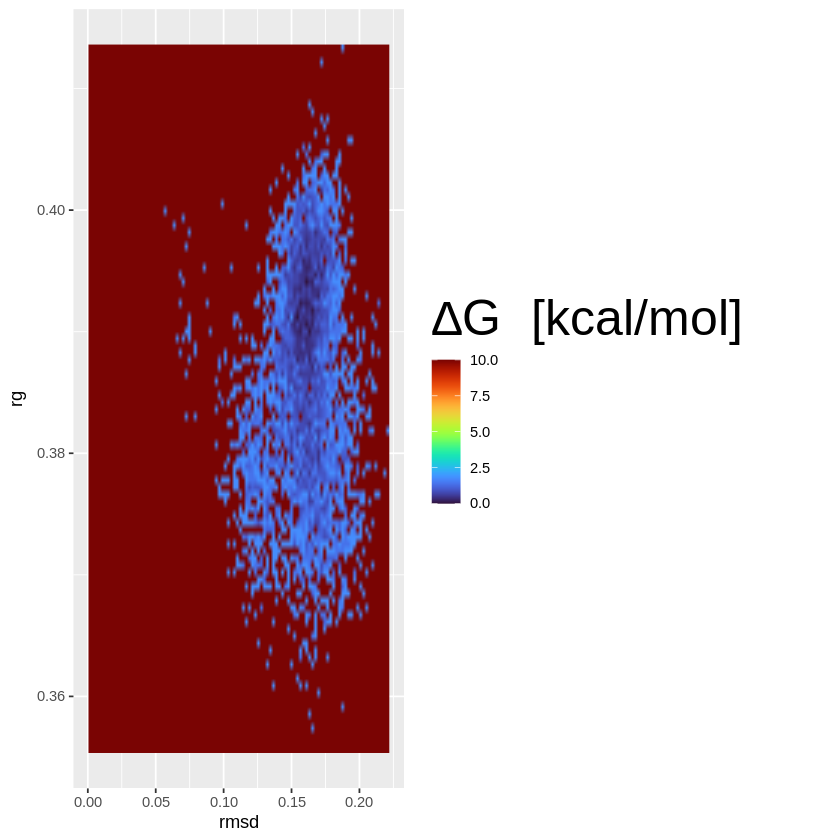

In [ ]:
#TITULO
library(ggplot2)
library(viridisLite)
lot1 <-ggplot(data, aes(rmsd, rg, fill = pmin(gbind, 10))) +
        geom_raster(interpolate = TRUE) +
        scale_fill_gradientn(colors = turbo(256),
                            limits = c(0,10),
                            name = expression(Delta*G~"[kcal/mol]")) +
        theme(legend.title = element_text(size = 30))

  lot1

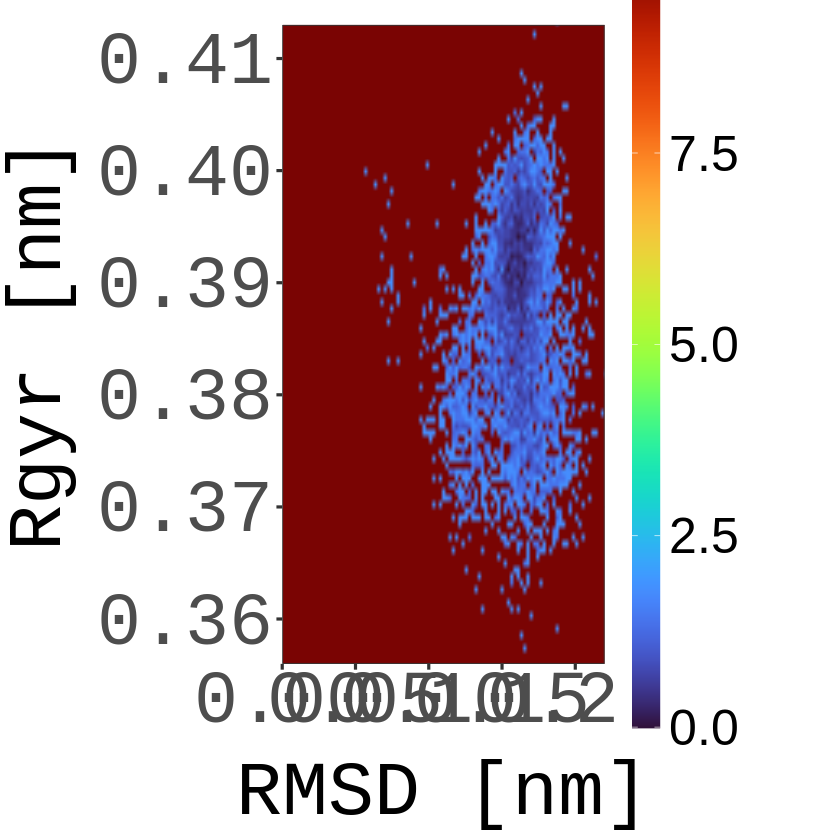

In [ ]:
library(ggplot2)
library(viridisLite)
library(grid)  # para unit()

plot1 <-ggplot(data, aes(rmsd, rg, fill = pmin(gbind, 10))) +
        ylab("Rgyr [nm]") +
        xlab("RMSD [nm]") +
        geom_raster(interpolate = TRUE) +
        scale_fill_gradientn(colors = turbo(256),
                            limits = c(0,10),
                            name = NULL) +
        theme_bw() +
        theme(axis.ticks = element_line(size = 0.9), # ancho de ticks
              axis.ticks.length = unit(3.5, "pt"), # largo de ticks,
              axis.text = element_text(family = "Roboto",size = 44),
              axis.title = element_text( family = "Roboto",size = 46),
              axis.title.x = element_text(margin = margin(t = 16)), # para alejar el titulo del ele x
              axis.title.y = element_text(margin = margin(r = 12)), # para alejar el título dle eje Y
              legend.text = element_text(size = 30),
              #panel.grid = element_blank(),
              plot.margin = margin(15, # arriba
                                   25, # derecha
                                   5.5, # abajo
                                   5.5)) + # izquierdo
        coord_cartesian(xlim=c(0,0.22), ylim = c(0.356, 0.413), expand = 0) + #expand = 0 elimina el espacio/margen alrededor del panel.
        #scale_y_continuous(breaks = seq(0, 0.18, by = 0.03)) +
        #scale_x_continuous(breaks = seq(0.489, 0.515, by = 0.005)) +
        guides(fill = guide_colorbar(direction = "vertical",
                                    barheight = unit(32, "lines"),  # barra alta
                                    barwidth  = unit(17, "pt"),
                                    title.position = "top"))

plot1
ggsave('/home/FEL_lig2.png', plot=plot1, dpi=600, width=12, height=8, units='in')

In [ ]:
data[data$gbind==0,]

,rmsd,rg,gbind
,<dbl>,<dbl>,<dbl>
6962,0.1544344,0.3911835,0
7267,0.1610792,0.3940972,0


**4_PLIP DYNAMICS** *texto en cursiva*


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Rows: 28 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): res, type
dbl (1): N

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


N,res,type,frecuencia
<dbl>,<chr>,<chr>,<dbl>
31,17-THR,H,1.005840
148,20-LEU,H,4.802077
155,65-GLN,H,5.029202
112,66-VAL,H,3.634004
172,89-LEU,H,5.580792
541,92-SER,HB,17.553537
155,99-PHE,H,5.029202
182,102-ASN,H,5.905256
71,105-ILE,H,2.303699


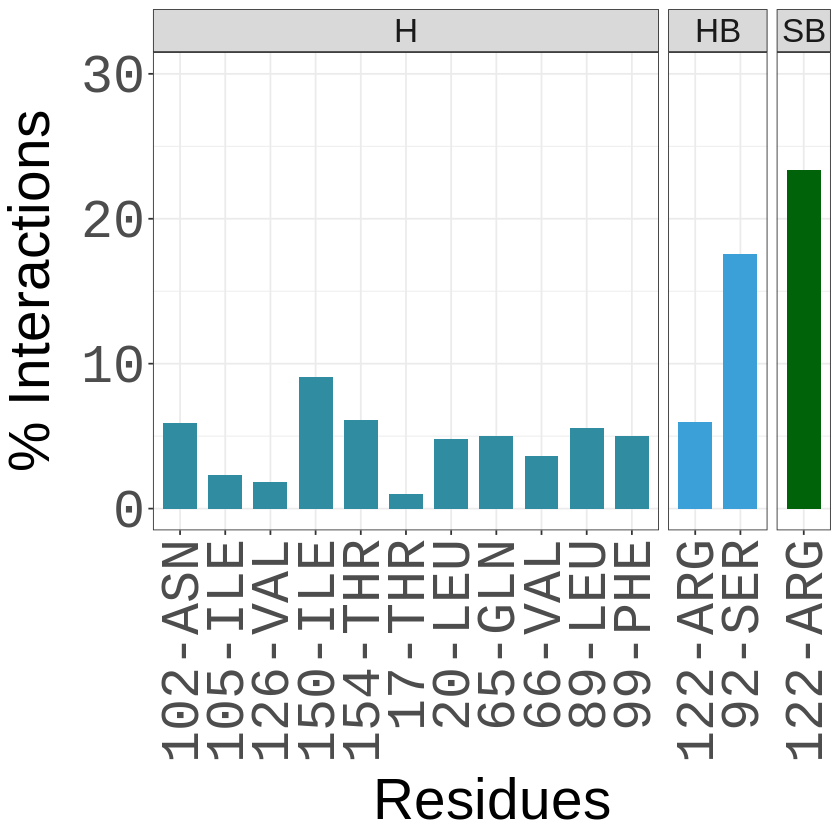

In [ ]:
library(ggplot2)
library(readr)
library(dplyr)
#library(svglite)

# Extracción de la data
data <- read_csv("/content/drive/MyDrive/3._CURSOS/2. Farmaco/unique.csv")

new_data <- mutate(data,frecuencia=N*100/(sum(N)))

# Seleccionando frecuencia mayores a 1
filter_data <- new_data[new_data$frecuencia>1,]
filter_data

# Generación del gráfico
plot <- ggplot(filter_data,aes(res,frecuencia, fill = type))
plot <- plot + geom_bar( stat="identity",width = 0.75) + theme_bw() +
  facet_grid(~type, scale = "free", space = "free") + # scale="free",space="free"
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1),
        axis.text = element_text(family = "Roboto",size = 32),
        axis.title = element_text( family = "Arial",size = 34),
        axis.title.x = element_text(margin = margin(t = 10)), # para alejar el titulo del ele x
        axis.title.y = element_text(margin = margin(r = 12)), # para alejar el título dle eje Y
        strip.text.x = element_text(size=20),
        legend.position = "none") +
  ylab("% Interactions") + xlab("Residues") + ylim(c(0,30)) +
  scale_fill_manual("Type",values=c("#308DA1","#3B9FD8","#006309"))

plot

# Guardar la imagen
ggsave('/content/drive/MyDrive/3._CURSOS/2. Farmaco/frecuencia_interaccion.png', plot=plot, dpi=600, width=12, height=8, units='in')
